# Look into the effect of Koleo Regularizer on separatability and complexity of desision boundary

/var/folders/p6/sxjm8c015r129mr_7x_q78kr0000gn/T/ipykernel_72135/1465827451.py:189: UserWarning: Glyph 12412 (\N{HIRAGANA LETTER BO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/p6/sxjm8c015r129mr_7x_q78kr0000gn/T/ipykernel_72135/1465827451.py:189: UserWarning: Glyph 12435 (\N{HIRAGANA LETTER N}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/p6/sxjm8c015r129mr_7x_q78kr0000gn/T/ipykernel_72135/1465827451.py:189: UserWarning: Glyph 12420 (\N{HIRAGANA LETTER YA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/p6/sxjm8c015r129mr_7x_q78kr0000gn/T/ipykernel_72135/1465827451.py:189: UserWarning: Glyph 12426 (\N{HIRAGANA LETTER RI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/p6/sxjm8c015r129mr_7x_q78kr0000gn/T/ipykernel_72135/1465827451.py:189: UserWarning: Glyph 12460 (\N{KATAKANA LETTER GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/p6/sxjm8c015r129mr_7x_q78kr0000gn/T/ipykern

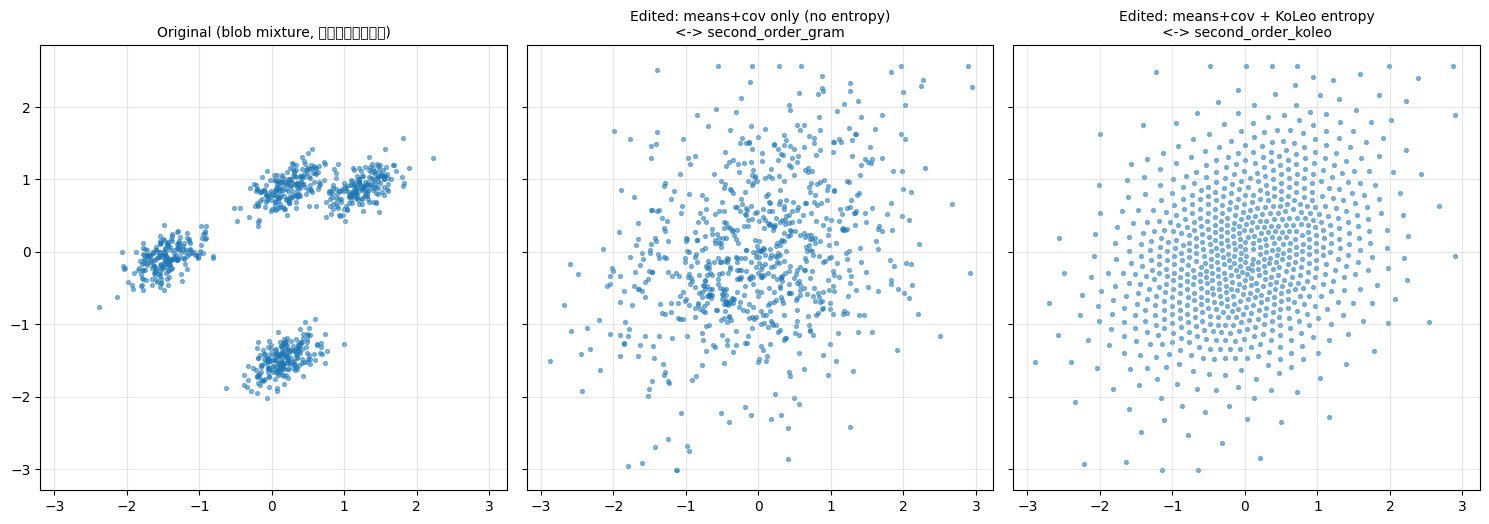

original     mean=[ 2.9802323e-09 -5.3644182e-09]  cov=
[[0.99875  0.299625]
 [0.299625 0.99875 ]]
  koleo(entropy proxy)=-3.7122
no_entropy   mean=[ 0.00204205 -0.00476418]  cov=
[[0.99559134 0.30122492]
 [0.30122492 0.99823725]]
  koleo(entropy proxy)=-2.8466
entropy      mean=[ 0.00650608 -0.00374217]  cov=
[[0.99199516 0.30045125]
 [0.30045125 0.99121875]]
  koleo(entropy proxy)=-1.9896


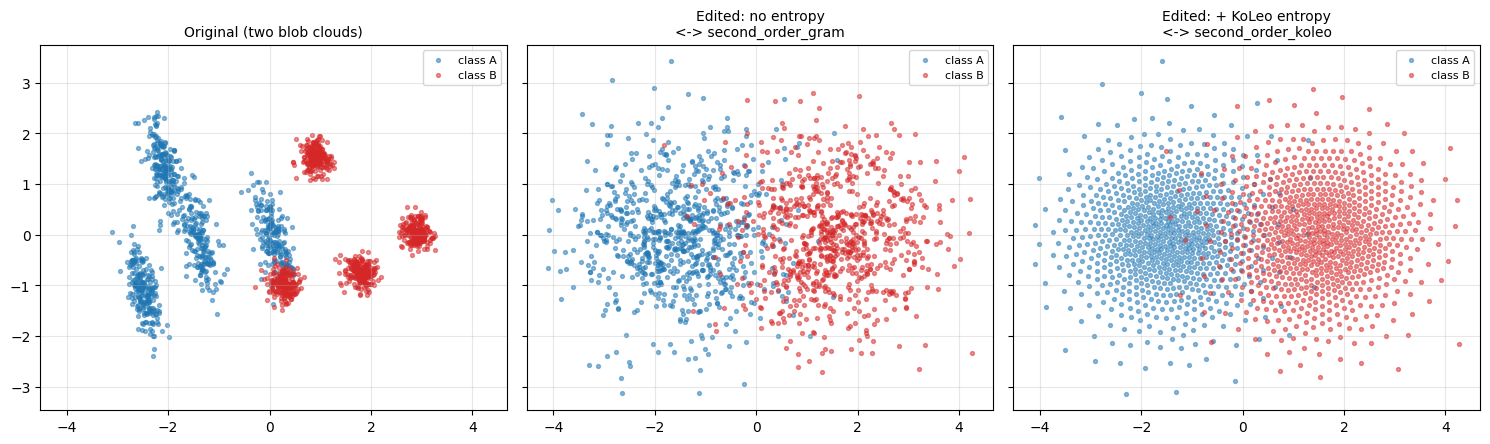

=== two-class separability & entropy ===
original       linear_acc=0.943  knn_acc=0.975  mlp_acc=0.974  koleo(entropy proxy)=-3.7084
no_entropy     linear_acc=0.938  knn_acc=0.926  mlp_acc=0.921  koleo(entropy proxy)=-2.8803
entropy(KoLeo) linear_acc=0.933  knn_acc=0.919  mlp_acc=0.916  koleo(entropy proxy)=-2.1547


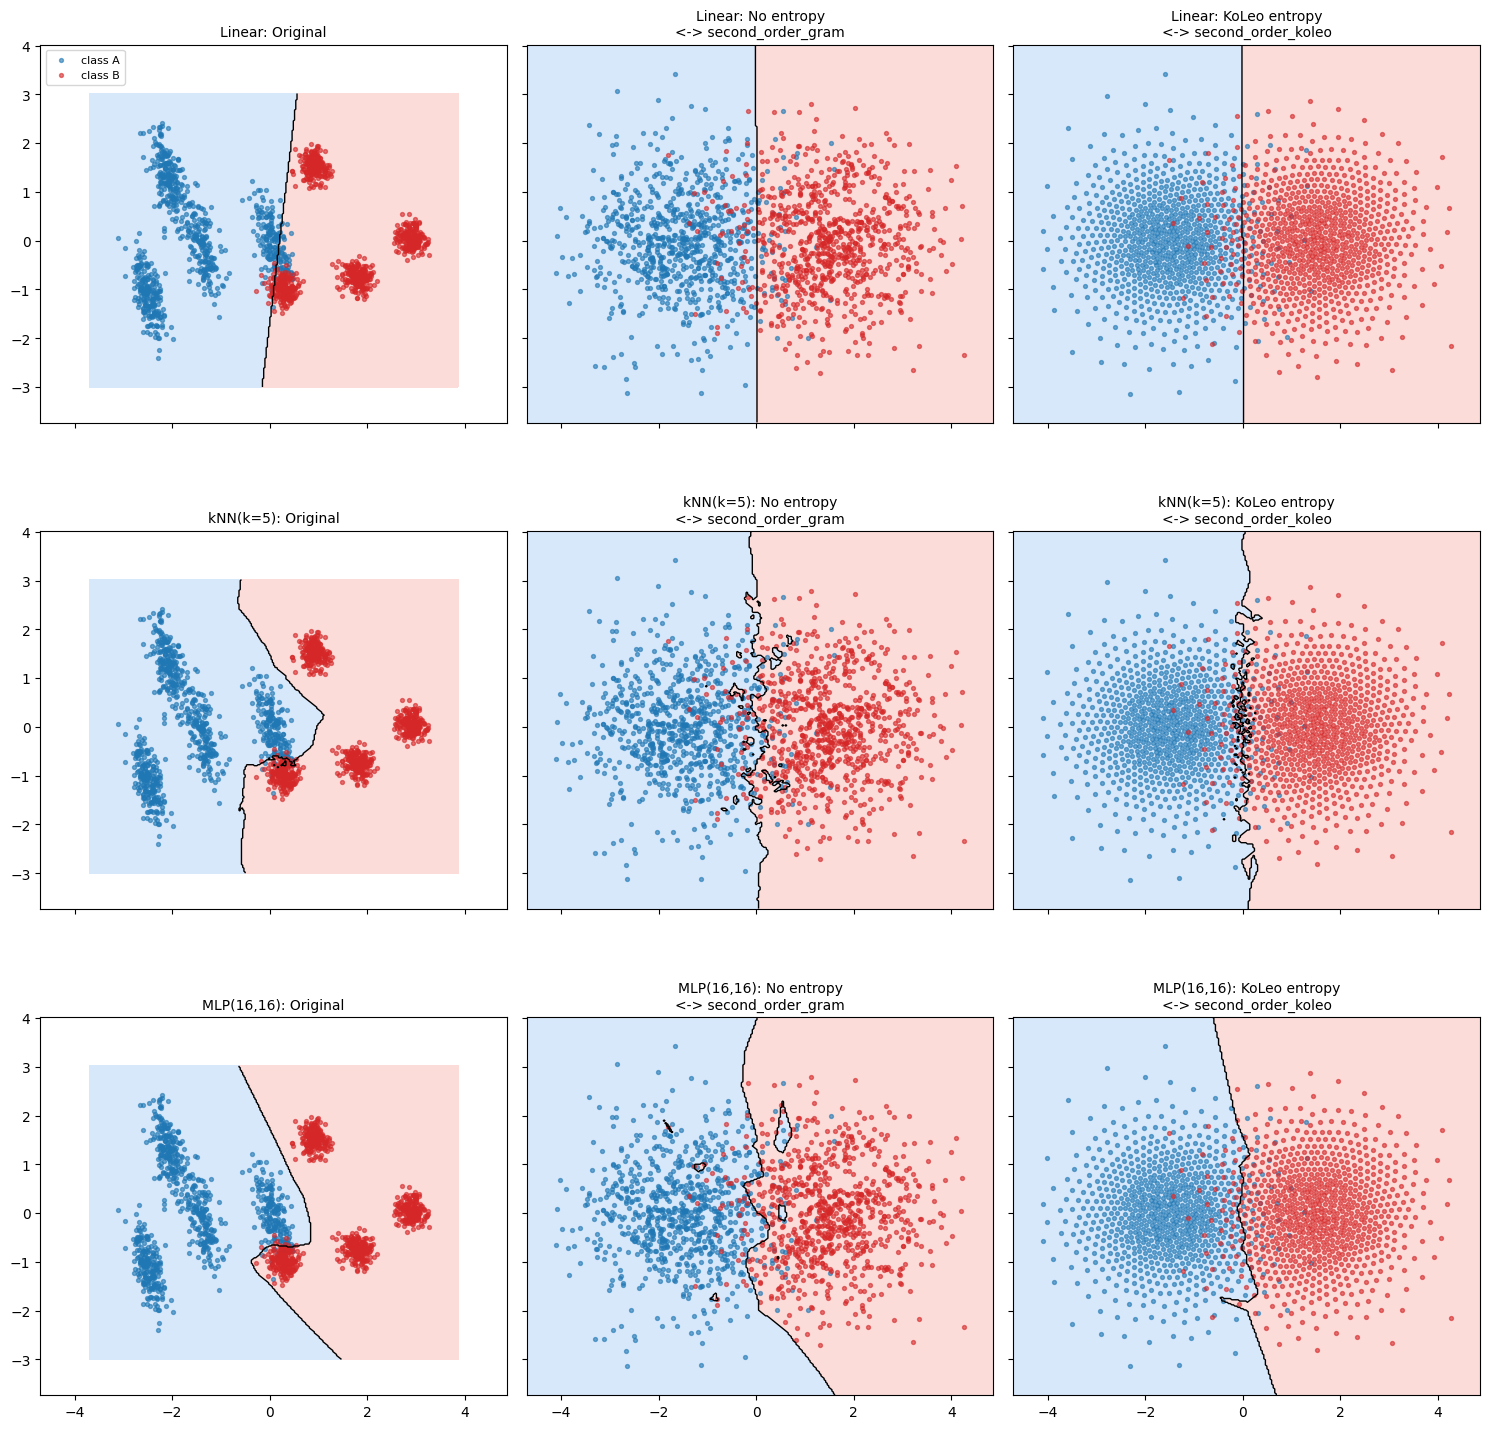

In [17]:
# %% [markdown]
# # モーメント編集(deletion)デモ: エントロピー項の有無で何が変わるか
#
# 実際のCIFAR-10実験(second_order_gram vs second_order_koleo)の縮図を、
# 2次元のトイ分布で可視化する。
#
# - 元分布: 複数のブロブ(塊)からなる「ぼんやりガウス風」分布
#   (純粋なガウスだと target mean/cov に合わせた時点で編集前後の差が
#   出なくなってしまうため、シルエットはガウス風だが中身にムラ・隙間が
#   残る分布を使う)
# - 編集方法A: means+cov のみ制約(エントロピー項なし) → second_order_gram 相当
# - 編集方法B: means+cov制約 + KoLeoエントロピー最大化 → second_order_koleo 相当
#
# 両方とも sigmoid変換によるbox制約を使い、本家 truncated_normal.py の設計を踏襲する。
#
# Google Colabにそのまま貼り付けて実行できる。GPU不要(2次元なのでCPUで十分高速)。

# %%
import warnings
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.exceptions import ConvergenceWarning

# MLPClassifierのConvergenceWarning等、トイデモの実行を妨げない警告を抑制する。
# (本番のCIFAR-10実験側には影響しない。このColabデモ内だけの措置)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn")

torch.manual_seed(0)
np.random.seed(0)
device = "cpu"  # 2Dなので十分速い。GPUがあれば "cuda" に変えてもよい。


# %% [markdown]
# ## 1. 元分布の生成(モーメントを正確に指定できるブロブ混合分布)
#
# 複数のガウス塊(ブロブ)を混ぜて生データを作った後、アフィン変換で
# 「指定した平均・共分散にちょうど一致する」ように標準化する。
# 全体のシルエットは(塊が集まって)ぼんやりガウス風に見えるが、
# 塊同士の隙間・密度ムラという形で非ガウス性(高次モーメント構造)が残る。
# ring版も比較用に残してある。

# %%
def make_blob_mixture_samples(n, mean, cov, seed=0, n_blobs=4, blob_std=0.25, spread=1.8):
    """
    複数のガウス塊を混ぜた「ぼんやりガウス風」の生データを作り、
    指定した mean/cov にちょうど一致するようアフィン変換する。
    """
    rng = np.random.default_rng(seed)
    centers = rng.normal(scale=spread, size=(n_blobs, 2))
    assign = rng.integers(0, n_blobs, size=n)
    raw = centers[assign] + rng.normal(scale=blob_std, size=(n, 2))

    raw_mean = raw.mean(axis=0)
    raw_cov = np.cov(raw.T)
    raw_cov_isqrt = np.linalg.inv(np.linalg.cholesky(raw_cov))
    standardized = (raw - raw_mean) @ raw_cov_isqrt.T

    target_L = np.linalg.cholesky(np.asarray(cov))
    out = standardized @ target_L.T + np.asarray(mean)
    return out.astype(np.float32)


def make_ring_samples(n, mean, cov, seed=0, ring_radius=3.0, ring_noise=0.35):
    """リング(ドーナツ)状の生データ版。比較用に残してある。"""
    rng = np.random.default_rng(seed)
    theta = rng.uniform(0, 2 * np.pi, n)
    r = rng.normal(ring_radius, ring_noise, n)
    raw = np.stack([r * np.cos(theta), r * np.sin(theta)], axis=1)

    raw_mean = raw.mean(axis=0)
    raw_cov = np.cov(raw.T)
    raw_cov_isqrt = np.linalg.inv(np.linalg.cholesky(raw_cov))
    standardized = (raw - raw_mean) @ raw_cov_isqrt.T

    target_L = np.linalg.cholesky(np.asarray(cov))
    out = standardized @ target_L.T + np.asarray(mean)
    return out.astype(np.float32)


# 使う生成関数をここで切り替える(blobs / ring)
make_samples = make_blob_mixture_samples


# %% [markdown]
# ## 2. 編集アルゴリズム(sigmoid変換によるbox制約、本家 truncated_normal.py の設計を踏襲)

# %%
def compute_covariance(X):
    Xc = X - X.mean(dim=0)
    return Xc.t() @ Xc / X.shape[0]


def koleo(x: torch.Tensor) -> torch.Tensor:
    """Kozachenko-Leonenko エントロピー推定量(最近傍距離の対数平均)。"""
    return torch.cdist(x, x).kthvalue(2).values.log().mean()


def edit_distribution(
    samples,
    box_low,
    box_high,
    use_entropy,
    n_steps=400,
    lr=0.05,
    koleo_weight=1e-2,
    rng_seed=42,
    device="cpu",
):
    """
    means + cov を目標データに一致させる。use_entropy=True ならさらに
    KoLeoエントロピーを最大化する。box制約は sigmoid reparametrization で実現。
    """
    torch.manual_seed(rng_seed)
    real = torch.as_tensor(samples, dtype=torch.float32, device=device)
    n, d = real.shape
    real_mean = real.mean(dim=0)
    real_cov = compute_covariance(real)

    low = torch.as_tensor(box_low, dtype=torch.float32, device=device)
    high = torch.as_tensor(box_high, dtype=torch.float32, device=device)
    span = high - low
    eps = 1e-6

    rng = torch.Generator(device=device).manual_seed(rng_seed)
    z0 = torch.empty(n, d, device=device).normal_(generator=rng)
    L = torch.linalg.cholesky(real_cov + 1e-6 * torch.eye(d, device=device))
    x0 = z0 @ L.t() + real_mean
    u0 = torch.clamp((x0 - low) / span, eps, 1 - eps)
    z = nn.Parameter(u0.logit())

    opt = torch.optim.Adam([z], lr=lr)
    for i in range(n_steps):
        opt.zero_grad()
        u = z.sigmoid()
        x = low + u * span
        fake_mean = x.mean(dim=0)
        fake_cov = compute_covariance(x)
        means_loss = (fake_mean - real_mean).norm() / real_mean.numel()
        cov_loss = (fake_cov - real_cov).norm() / (d * d)
        loss = means_loss + cov_loss
        if use_entropy:
            loss = loss - koleo_weight * koleo(x)
        loss.backward()
        opt.step()

    with torch.no_grad():
        u = z.sigmoid()
        x_final = low + u * span
    return x_final.numpy()


# %% [markdown]
# ## 3. 単一分布での比較: 元分布 vs 編集A(エントロピーなし) vs 編集B(エントロピーあり)

# %%
n_samples = 800
target_mean = np.array([0.0, 0.0])
target_cov = np.array([[1.0, 0.3], [0.3, 1.0]])

original = make_samples(n_samples, target_mean, target_cov, seed=1)

box_low = original.min(axis=0) - 1.0
box_high = original.max(axis=0) + 1.0

edited_no_entropy = edit_distribution(
    original, box_low, box_high, use_entropy=False, n_steps=400, lr=0.05, rng_seed=42,
)
edited_entropy = edit_distribution(
    original, box_low, box_high, use_entropy=True, n_steps=400, lr=0.05,
    koleo_weight=1e-2, rng_seed=42,
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, data, title in zip(
    axes,
    [original, edited_no_entropy, edited_entropy],
    ["Original (blob mixture, ぼんやりガウス風)",
     "Edited: means+cov only (no entropy)\n<-> second_order_gram",
     "Edited: means+cov + KoLeo entropy\n<-> second_order_koleo"],
):
    ax.scatter(data[:, 0], data[:, 1], s=8, alpha=0.5)
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("moment_editing_demo_single.png", dpi=150)
plt.show()

with torch.no_grad():
    for name, data in [("original", original), ("no_entropy", edited_no_entropy),
                        ("entropy", edited_entropy)]:
        t = torch.as_tensor(data, dtype=torch.float32)
        print(f"{name:12s} mean={t.mean(0).numpy()}  "
              f"cov=\n{compute_covariance(t).numpy()}\n"
              f"  koleo(entropy proxy)={koleo(t).item():.4f}")


# %% [markdown]
# ## 4. 2クラス版: 編集後にクラス間の重なりがどう変わるか

# %%
mean_a = np.array([-1.5, 0.0])
mean_b = np.array([1.5, 0.0])
cov_shared = np.array([[1.0, 0.0], [0.0, 1.0]])

orig_a = make_samples(n_samples, mean_a, cov_shared, seed=10)
orig_b = make_samples(n_samples, mean_b, cov_shared, seed=20)

box_low2 = np.minimum(orig_a.min(axis=0), orig_b.min(axis=0)) - 1.0
box_high2 = np.maximum(orig_a.max(axis=0), orig_b.max(axis=0)) + 1.0

def edit_pair(use_entropy, koleo_weight=1e-2):
    ea = edit_distribution(orig_a, box_low2, box_high2, use_entropy=use_entropy,
                            n_steps=400, lr=0.05, koleo_weight=koleo_weight, rng_seed=42)
    eb = edit_distribution(orig_b, box_low2, box_high2, use_entropy=use_entropy,
                            n_steps=400, lr=0.05, koleo_weight=koleo_weight, rng_seed=43)
    return ea, eb

no_ent_a, no_ent_b = edit_pair(use_entropy=False)
ent_a, ent_b = edit_pair(use_entropy=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, (da, db), title in zip(
    axes,
    [(orig_a, orig_b), (no_ent_a, no_ent_b), (ent_a, ent_b)],
    ["Original (two blob clouds)",
     "Edited: no entropy\n<-> second_order_gram",
     "Edited: + KoLeo entropy\n<-> second_order_koleo"],
):
    ax.scatter(da[:, 0], da[:, 1], s=8, alpha=0.5, label="class A", color="tab:blue")
    ax.scatter(db[:, 0], db[:, 1], s=8, alpha=0.5, label="class B", color="tab:red")
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("moment_editing_demo_two_classes.png", dpi=150)
plt.show()


# %% [markdown]
# ## 5. 定量評価: エントロピー(KoLeo値)と分類しやすさ(記憶の要否の代理指標)
#
# 分類が簡単(精度が高い)ほど、モデルは複雑な決定境界を「記憶」する必要がなく、
# LLC(複雑さ)が低くなると予想される。逆にクラスが重なって分類が難しいほど、
# 高精度化には複雑な決定境界の記憶が必要になり、LLCが高くなると予想される。

# %%
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# 簡単なMLP(2隠れ層)。容量は小さめにして、境界の複雑さの違いが
# 「モデル側の表現力不足」ではなくデータ側の性質から出るようにする。
def make_mlp():
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(32, 32), activation="relu",
                       max_iter=8000, random_state=0,
                       early_stopping=False, n_iter_no_change=3000),
    )


def evaluate_pair(name, da, db):
    X = np.concatenate([da, db], axis=0)
    y = np.concatenate([np.zeros(len(da)), np.ones(len(db))])
    lin_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    lin_acc = cross_val_score(lin_clf, X, y, cv=5).mean()
    knn_acc = cross_val_score(KNeighborsClassifier(n_neighbors=5), X, y, cv=5).mean()
    mlp_acc = cross_val_score(make_mlp(), X, y, cv=5).mean()
    combined = torch.as_tensor(X, dtype=torch.float32)
    ent = koleo(combined).item()
    print(f"{name:14s} linear_acc={lin_acc:.3f}  knn_acc={knn_acc:.3f}  "
          f"mlp_acc={mlp_acc:.3f}  koleo(entropy proxy)={ent:.4f}")

print("=== two-class separability & entropy ===")
evaluate_pair("original", orig_a, orig_b)
evaluate_pair("no_entropy", no_ent_a, no_ent_b)
evaluate_pair("entropy(KoLeo)", ent_a, ent_b)


# %% [markdown]
# ## 6. 決定境界の可視化
#
# 分類器を(CVではなく)全データで学習し、決定境界そのものを描く。
# no_entropy版は「塊の隙間」を縫うようなギザギザした境界になりやすく、
# entropy版はより滑らか(単純)な境界になりやすい、という予想を直接見る。
# 線形(LogisticRegression)・kNN(局所的な決定則)・簡単なMLP(小さなニューラル
# ネットワーク、実際のCIFAR-10実験でのモデルの立場に一番近い)の3種類を並べる。

# %%
def plot_decision_boundary(ax, clf, da, db, title, grid_pad=0.6, grid_n=300):
    X = np.concatenate([da, db], axis=0)
    y = np.concatenate([np.zeros(len(da)), np.ones(len(db))])
    clf.fit(X, y)

    x_min, x_max = X[:, 0].min() - grid_pad, X[:, 0].max() + grid_pad
    y_min, y_max = X[:, 1].min() - grid_pad, X[:, 1].max() + grid_pad
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, grid_n), np.linspace(y_min, y_max, grid_n)
    )
    zz = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=["#cfe3fb", "#fbd4d0"], alpha=0.8)
    ax.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=1.0)
    ax.scatter(da[:, 0], da[:, 1], s=8, alpha=0.6, color="tab:blue", label="class A")
    ax.scatter(db[:, 0], db[:, 1], s=8, alpha=0.6, color="tab:red", label="class B")
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")


conditions = [
    ("Original", orig_a, orig_b),
    ("No entropy\n<-> second_order_gram", no_ent_a, no_ent_b),
    ("KoLeo entropy\n<-> second_order_koleo", ent_a, ent_b),
]

fig, axes = plt.subplots(3, 3, figsize=(15, 15), sharex=True, sharey=True)
for col, (title, da, db) in enumerate(conditions):
    linear_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    plot_decision_boundary(axes[0, col], linear_clf, da, db, f"Linear: {title}")

    knn_clf = KNeighborsClassifier(n_neighbors=5)
    plot_decision_boundary(axes[1, col], knn_clf, da, db, f"kNN(k=5): {title}")

    mlp_clf = make_mlp()
    plot_decision_boundary(axes[2, col], mlp_clf, da, db, f"MLP(16,16): {title}")

axes[0, 0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig("moment_editing_demo_decision_boundaries.png", dpi=150)
plt.show()